# Classificador de Imagens com CNN (CIFAR-10)

## Objetivo

Treinar uma **Rede Neural Convolucional (CNN)** para classificar imagens em 10 categorias
(avião, automóvel, pássaro, gato, cervo, cachorro, sapo, cavalo, navio e caminhão).

Roteiro:

1. Fundamentos de imagens digitais: pixels, canais, resolução e normalização.
2. Separação treino / validação / teste.
3. **CNN base** (a primeira CNN da aula).
4. **CNN melhorada**: Batch Normalization, Dropout, Data Augmentation e callbacks.
5. Comparação das curvas de treino e validação.
6. Avaliação no teste: acurácia, matriz de confusão e acerto por classe.
7. O que a CNN "enxerga": filtros e mapas de características.
8. Previsões em imagens do teste e em uma imagem nova.

In [1]:
from pathlib import Path

# Biblioteca para operações numéricas
import numpy as np

# Para visualização
import matplotlib.pyplot as plt

# Para redes neurais
import tensorflow as tf

# Interface de alto nível para construir redes neurais
from tensorflow import keras

# Importando as camadas da rede
from tensorflow.keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    MaxPooling2D,
    RandomFlip,
    RandomTranslation,
)

# Funções utilitárias para trabalhar com imagens
from tensorflow.keras.utils import load_img, img_to_array

# Reprodutibilidade
SEED = 42
keras.utils.set_random_seed(SEED)

# Caminhos do projeto (o notebook roda de dentro da pasta notebooks/)
ROOT = Path.cwd().parents[0]
MODELS_DIR = ROOT / "models"
FIGURES_DIR = ROOT / "reports" / "figures"
INTERIM_DIR = ROOT / "data" / "interim"

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Carregar a base CIFAR-10

In [2]:
# Carregar a base CIFAR
(X_train_full, y_train_full), (X_test_raw, y_test) = keras.datasets.cifar10.load_data()

# y vem como coluna (N, 1): achatamos para (N,)
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

class_names = ["avião", "automóvel", "pássaro", "gato", "cervo",
               "cachorro", "sapo", "cavalo", "navio", "caminhão"]

print("Formato de X_train:", X_train_full.shape)
print("Formato de y_train:", y_train_full.shape)
print("Formato de X_test: ", X_test_raw.shape)
print("Formato de y_test: ", y_test.shape)

Formato de X_train: (50000, 32, 32, 3)
Formato de y_train: (50000,)
Formato de X_test:  (10000, 32, 32, 3)
Formato de y_test:  (10000,)


## 2. Fundamentos de imagens digitais

Para o computador, uma imagem colorida é um **tensor** `altura × largura × canais`:

- **resolução:** 32 × 32 pixels;
- **canais:** 3 (R = vermelho, G = verde, B = azul);
- **pixel:** cada canal guarda um número inteiro de **0** (ausência daquela cor) a **255**
  (intensidade máxima).

In [3]:
image = X_train_full[0]

print("Formato de uma imagem:", image.shape)
print("Tipo dos pixels:", image.dtype)
print("Menor e maior valor:", image.min(), image.max())
print("\nPixel (0, 0) em RGB:", image[0, 0])

Formato de uma imagem: (32, 32, 3)
Tipo dos pixels: uint8
Menor e maior valor: 0 255

Pixel (0, 0) em RGB: [59 62 63]


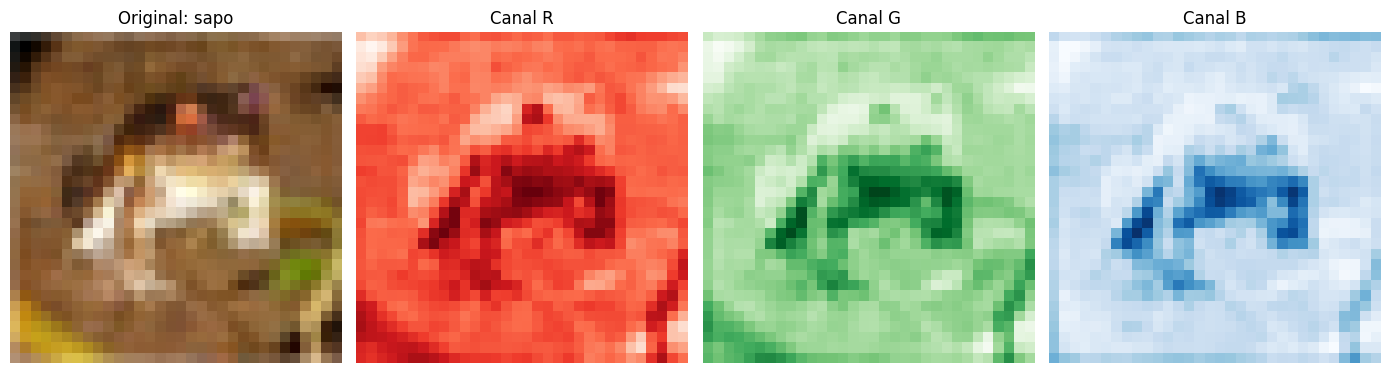

In [4]:
# A mesma imagem separada em seus 3 canais
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(image)
axes[0].set_title(f"Original: {class_names[y_train_full[0]]}")

for i, (channel, cmap) in enumerate(zip(["R", "G", "B"], ["Reds", "Greens", "Blues"]), start=1):
    axes[i].imshow(image[:, :, i - 1], cmap=cmap)
    axes[i].set_title(f"Canal {channel}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

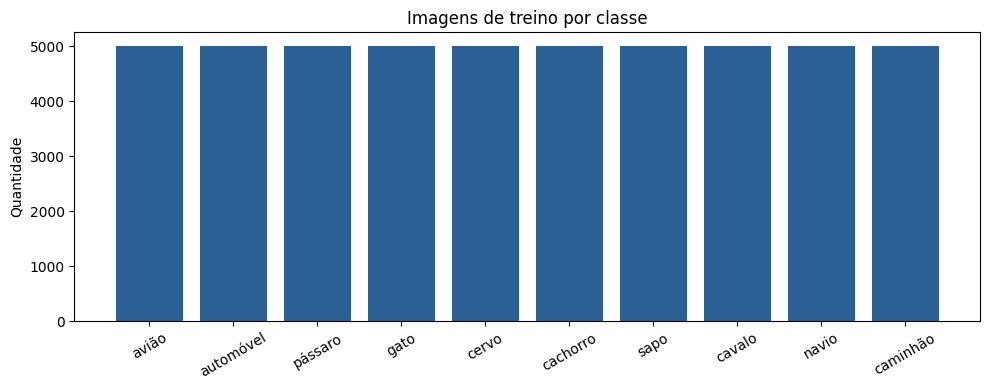

In [5]:
# Quantidade de imagens por classe: a base é balanceada
counts = np.bincount(y_train_full, minlength=10)

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts, color="#2B6094")
plt.title("Imagens de treino por classe")
plt.ylabel("Quantidade")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

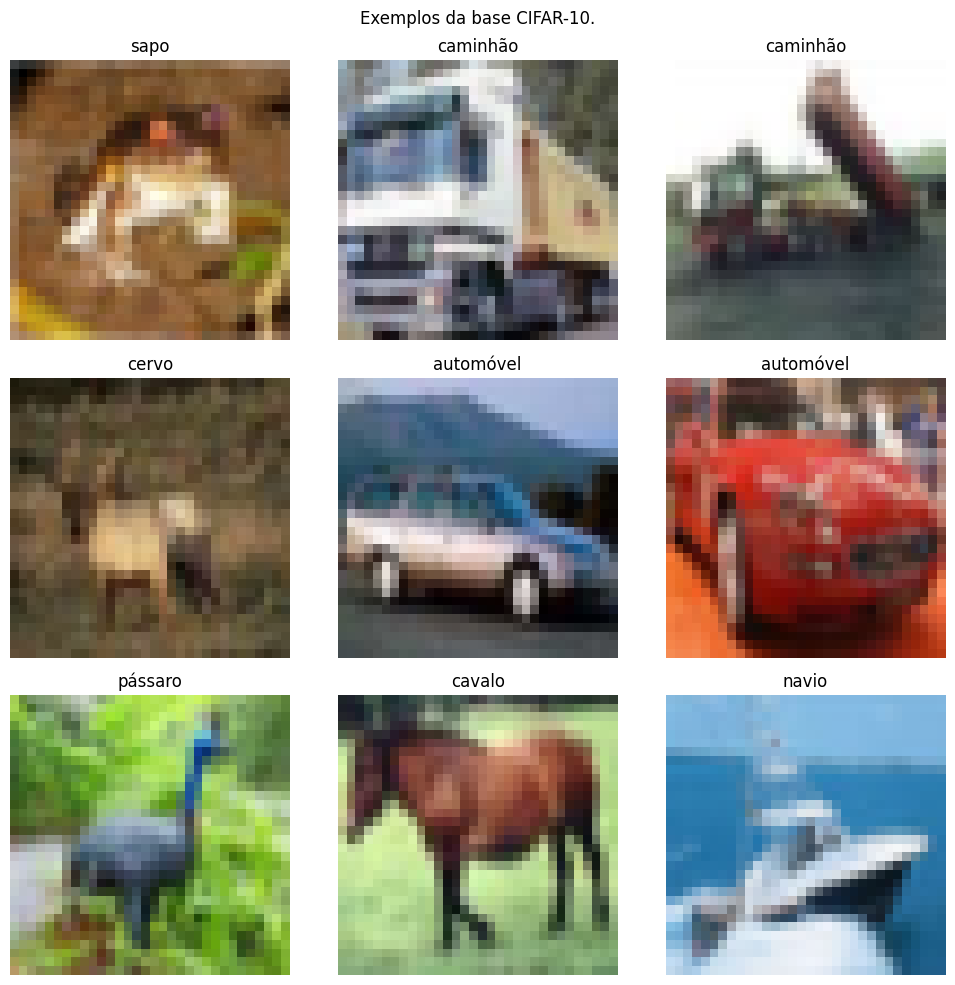

In [6]:
# Plotar algumas imagens
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train_full[i])
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")
plt.suptitle("Exemplos da base CIFAR-10.")
plt.tight_layout()
plt.show()

### Normalização

Redes neurais aprendem por gradiente e funcionam melhor com valores pequenos e na mesma escala.
Dividimos os pixels por 255 para levá-los ao intervalo **[0, 1]**.

In [7]:
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

print("Depois da normalização:", X_train_full.min(), "a", X_train_full.max())

Depois da normalização: 0.0 a 1.0


## 3. Separação treino / validação / teste

- **treino (45.000):** a rede aprende os pesos;
- **validação (5.000):** acompanhamos o treino, escolhemos o melhor modelo e o Early Stopping;
- **teste (10.000):** fica guardado até a avaliação final.

In [8]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X_train_full))

n_val = 5_000
val_idx, train_idx = indices[:n_val], indices[n_val:]

X_train, y_train = X_train_full[train_idx], y_train_full[train_idx]
X_val, y_val = X_train_full[val_idx], y_train_full[val_idx]

print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")

Treino: 45000 | Validação: 5000 | Teste: 10000


## 4. CNN base

Arquitetura da aula:

```
Imagem 32×32×3
  → [Conv 16 filtros 3×3 + ReLU] → MaxPooling 2×2
  → [Conv 32 filtros 3×3 + ReLU] → MaxPooling 2×2
  → [Conv 64 filtros 3×3 + ReLU] → MaxPooling 2×2
  → Flatten → Dense 64 (ReLU) → Dense 10 (Softmax)
```

- **Convolução:** um filtro desliza sobre a imagem e detecta padrões locais (bordas, cores, texturas).
- **Pooling:** reduz o tamanho do mapa de características mantendo o que é mais forte.
- **Flatten + Dense:** transformam os mapas em um vetor e decidem a classe.
- **Softmax:** devolve uma probabilidade para cada uma das 10 classes (somam 1).

In [9]:
keras.utils.set_random_seed(SEED)

base_model = keras.Sequential(name="cnn_base")

# Camada de Entrada
base_model.add(Input(shape=(32, 32, 3)))

# Bloco 1
base_model.add(Conv2D(filters=16, kernel_size=(3, 3), activation="relu"))
base_model.add(MaxPooling2D(pool_size=(2, 2)))

# Bloco 2
base_model.add(Conv2D(filters=32, kernel_size=(3, 3), activation="relu"))
base_model.add(MaxPooling2D(pool_size=(2, 2)))

# Bloco 3
base_model.add(Conv2D(filters=64, kernel_size=(3, 3), activation="relu"))
base_model.add(MaxPooling2D(pool_size=(2, 2)))

# Transição CNN => Dense (Totalmente conectada)
base_model.add(Flatten())
base_model.add(Dense(64, activation="relu"))
base_model.add(Dense(10, activation="softmax"))

# Compilar
base_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Resumo da arquitetura do modelo
base_model.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,682 (158.91 KB)

 Trainable params: 40,682 (158.91 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history_base = base_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.3916 - loss: 1.6525 - val_accuracy: 0.4832 - val_loss: 1.4409
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5113 - loss: 1.3568 - val_accuracy: 0.5488 - val_loss: 1.2841
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5639 - loss: 1.2329 - val_accuracy: 0.5750 - val_loss: 1.2017
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5987 - loss: 1.1415 - val_accuracy: 0.5964 - val_loss: 1.1428
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6254 - loss: 1.0722 - val_accuracy: 0.6128 - val_loss: 1.1044
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6450 - loss: 1.0163 - val_accuracy: 0.6270 - val_loss: 1.0728
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6600 - loss: 0.9707 - val_accuracy: 0.6352 - val_loss: 1.0588
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6739 - loss: 0.9325 - val_accuracy:

## 5. CNN melhorada

Problemas típicos da CNN base: ela é pequena e começa a decorar o treino (overfitting).
Melhorias aplicadas:

| Técnica | Para que serve |
|---|---|
| **Data Augmentation** (espelhar e deslocar) | Cria variações das imagens de treino: a rede vê "novas" imagens e generaliza melhor |
| **Dois Conv por bloco + `padding="same"`** | Mais capacidade para aprender padrões, sem encolher a imagem a cada convolução |
| **Batch Normalization** | Estabiliza e acelera o treino |
| **Dropout** | Desliga neurônios aleatoriamente: evita depender de poucos caminhos |
| **EarlyStopping** | Para quando a validação não melhora e restaura os melhores pesos |
| **ReduceLROnPlateau** | Diminui o learning rate quando o treino estabiliza |
| **ModelCheckpoint** | Salva o melhor modelo em `models/` |

> A Data Augmentation só atua no **treino**; na validação, no teste e na previsão as imagens
> passam sem alteração.

In [11]:
def conv_block(model, filters, dropout):
    # Conv -> BN -> Conv -> BN -> MaxPool -> Dropout
    model.add(Conv2D(filters, (3, 3), padding="same", activation="relu"))
    model.add(BatchNormalization())
    model.add(Conv2D(filters, (3, 3), padding="same", activation="relu"))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(dropout))


keras.utils.set_random_seed(SEED)

model = keras.Sequential(name="cnn_melhorada")
model.add(Input(shape=(32, 32, 3)))

# Data Augmentation
model.add(RandomFlip("horizontal"))
model.add(RandomTranslation(0.1, 0.1))

conv_block(model, 32, 0.2)    # 32×32 -> 16×16
conv_block(model, 64, 0.3)    # 16×16 -> 8×8
conv_block(model, 128, 0.4)   # 8×8   -> 4×4

model.add(Flatten())
model.add(Dense(128, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "cnn_melhorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [12]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "classificador_cifar10.keras"

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", save_best_only=True),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks,
)

print("Épocas treinadas:", len(history.history["loss"]))
print("Melhor modelo salvo em:", MODEL_PATH)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 98s 128ms/step - accuracy: 0.3920 - loss: 1.7942 - val_accuracy: 0.5328 - val_loss: 1.2852 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 119ms/step - accuracy: 0.5614 - loss: 1.2262 - val_accuracy: 0.5700 - val_loss: 1.2757 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 109s 155ms/step - accuracy: 0.6347 - loss: 1.0392 - val_accuracy: 0.6628 - val_loss: 0.9474 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 118s 168ms/step - accuracy: 0.6746 - loss: 0.9345 - val_accuracy: 0.6690 - val_loss: 0.9351 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 107s 152ms/step - accuracy: 0.7000 - loss: 0.8641 - val_accuracy: 0.7180 - val_loss: 0.8013 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 16754s 24s/step - accuracy: 0.7210 - loss: 0.8044 - val_accuracy: 0.7130 - val_loss: 0.8430 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 162s 230ms/step - accuracy

## 6. Curvas de acurácia e loss

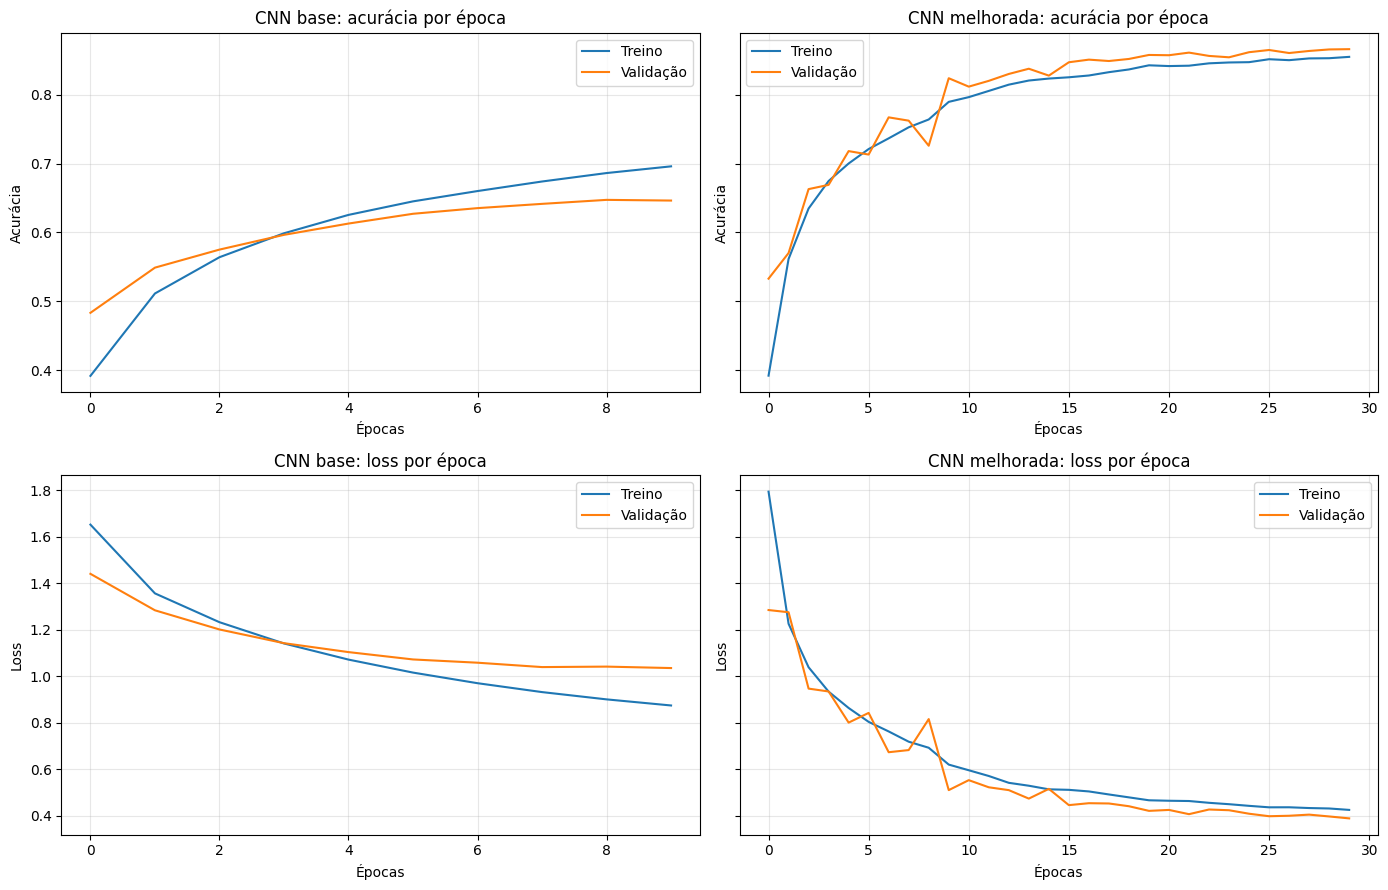

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")

for col, (hist, title) in enumerate([(history_base, "CNN base"), (history, "CNN melhorada")]):
    axes[0, col].plot(hist.history["accuracy"], label="Treino")
    axes[0, col].plot(hist.history["val_accuracy"], label="Validação")
    axes[0, col].set(title=f"{title}: acurácia por época", xlabel="Épocas", ylabel="Acurácia")

    axes[1, col].plot(hist.history["loss"], label="Treino")
    axes[1, col].plot(hist.history["val_loss"], label="Validação")
    axes[1, col].set(title=f"{title}: loss por época", xlabel="Épocas", ylabel="Loss")

for ax in axes.ravel():
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Como ler as curvas:**

- **CNN base:** a acurácia de treino tende a continuar subindo enquanto a de validação
  estaciona, e a distância entre as curvas aumenta. Esse é o sinal de **overfitting**: a rede
  começa a decorar o treino.
- **CNN melhorada:** treino e validação andam juntos. A regularização (augmentation, dropout,
  batch normalization) faz a rede **generalizar**.

## 7. Avaliação no conjunto de teste

In [14]:
base_loss, base_acc = base_model.evaluate(X_test, y_test, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"CNN base      -> acurácia no teste: {base_acc:.2%} | loss: {base_loss:.4f}")
print(f"CNN melhorada -> acurácia no teste: {test_acc:.2%} | loss: {test_loss:.4f}")
print(f"Chute aleatório (10 classes): {1 / 10:.0%}")

CNN base      -> acurácia no teste: 64.83% | loss: 1.0287
CNN melhorada -> acurácia no teste: 86.55% | loss: 0.4163
Chute aleatório (10 classes): 10%


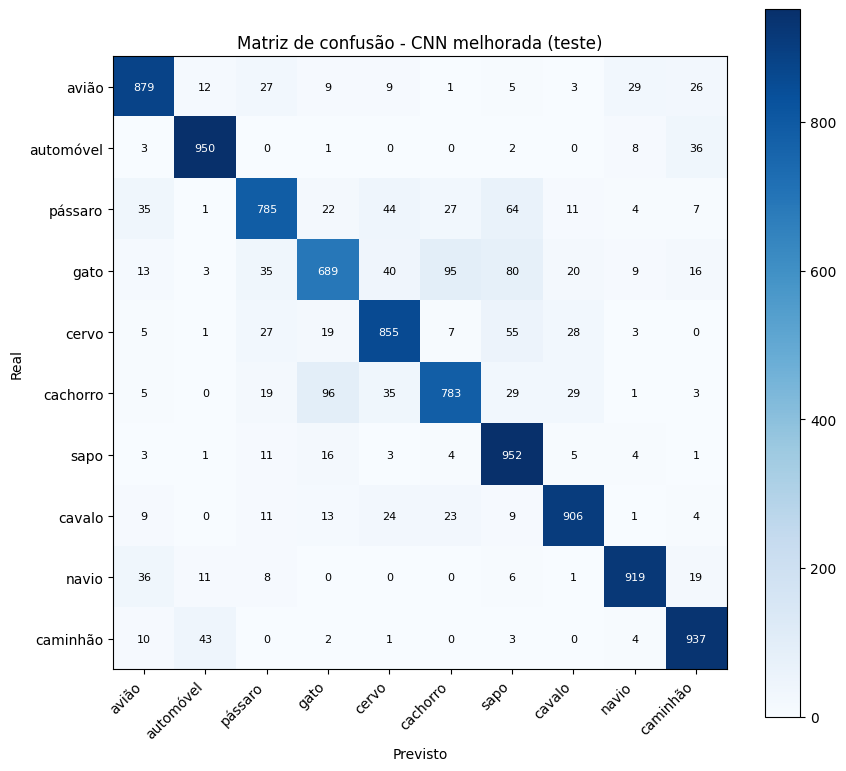

In [15]:
# Previsões da CNN melhorada para todo o teste
test_probs = model.predict(X_test, verbose=0)
test_pred = np.argmax(test_probs, axis=1)

# Matriz de confusão: linha = classe real, coluna = classe prevista
confusion = tf.math.confusion_matrix(y_test, test_pred, num_classes=10).numpy()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(confusion, cmap="Blues")

ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)
ax.set(xlabel="Previsto", ylabel="Real", title="Matriz de confusão - CNN melhorada (teste)")

for i in range(10):
    for j in range(10):
        color = "white" if confusion[i, j] > confusion.max() / 2 else "black"
        ax.text(j, i, confusion[i, j], ha="center", va="center", color=color, fontsize=8)

fig.colorbar(im, ax=ax)
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "confusion_matrix_cifar10.png", dpi=150)
plt.show()

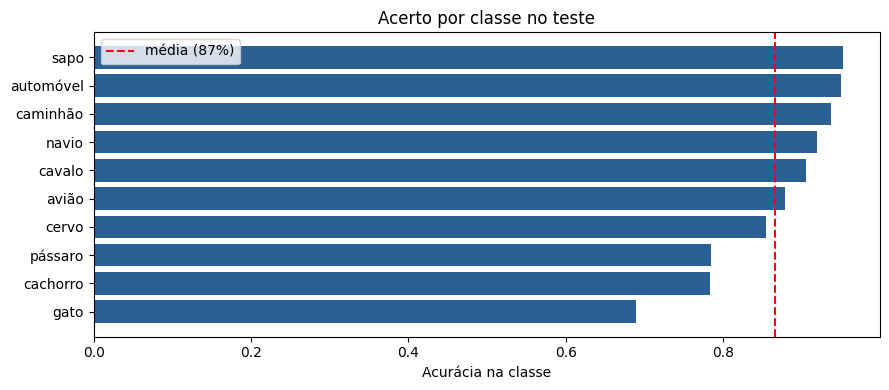

Confusões mais frequentes:
   cachorro classificado como gato     : 96
       gato classificado como cachorro : 95
       gato classificado como sapo     : 80
    pássaro classificado como sapo     : 64
      cervo classificado como sapo     : 55


In [16]:
# Acerto por classe (recall de cada classe)
per_class = confusion.diagonal() / confusion.sum(axis=1)
order = np.argsort(per_class)

plt.figure(figsize=(9, 4))
plt.barh(np.array(class_names)[order], per_class[order], color="#2B6094")
plt.axvline(test_acc, color="red", linestyle="--", label=f"média ({test_acc:.0%})")
plt.xlabel("Acurácia na classe")
plt.title("Acerto por classe no teste")
plt.legend()
plt.tight_layout()
plt.show()

# Pares de classes que a rede mais confunde
off_diagonal = confusion.copy()
np.fill_diagonal(off_diagonal, 0)
top = np.dstack(np.unravel_index(np.argsort(off_diagonal.ravel())[::-1][:5], off_diagonal.shape))[0]

print("Confusões mais frequentes:")
for real, pred in top:
    print(f"  {class_names[real]:>9} classificado como {class_names[pred]:<9}: {off_diagonal[real, pred]}")

**Leitura:** as classes de **veículos** (automóvel, caminhão, navio, avião) costumam ter o
maior acerto. As de **animais** parecidos entre si, principalmente **gato × cachorro**, são as
mais difíceis: em 32×32 pixels, os detalhes que diferenciam esses animais quase desaparecem.

## 8. O que a CNN "enxerga"

A primeira camada convolucional aprende **filtros** 3×3. Ao passar uma imagem por eles, cada
filtro gera um **mapa de características**, que destaca um tipo de padrão (bordas, cores).

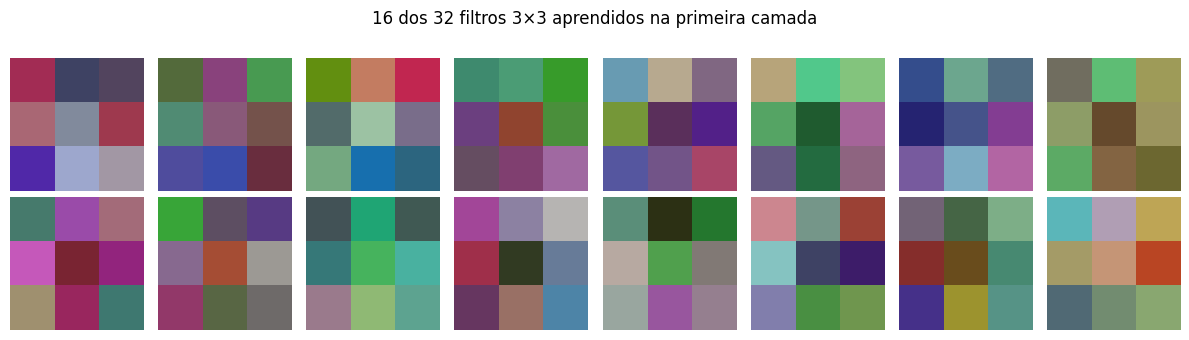

In [17]:
# Primeira camada convolucional da CNN melhorada
first_conv = next(layer for layer in model.layers if isinstance(layer, Conv2D))
filters, _ = first_conv.get_weights()

# Normaliza para [0, 1] só para visualizar
filters = (filters - filters.min()) / (filters.max() - filters.min())

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(filters[:, :, :, i])
    ax.axis("off")
plt.suptitle("16 dos 32 filtros 3×3 aprendidos na primeira camada")
plt.tight_layout()
plt.show()

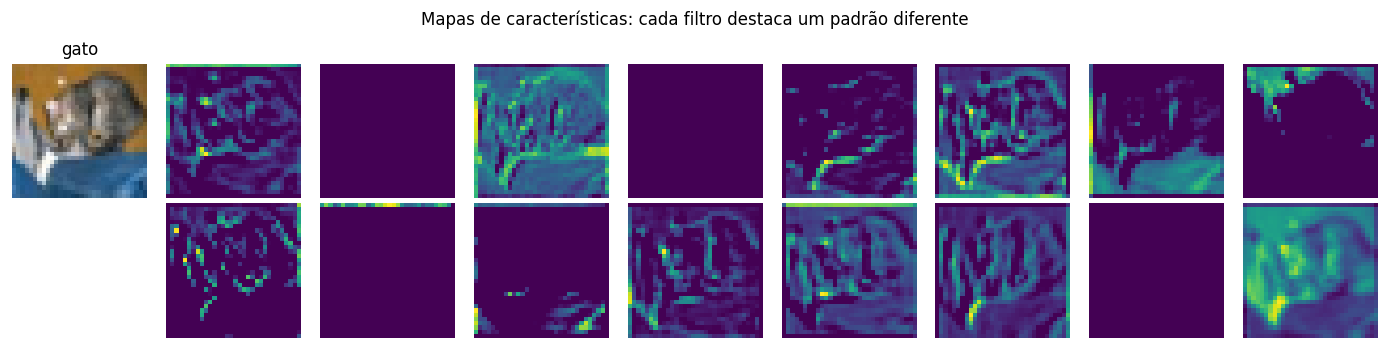

In [18]:
# Mapas de características de uma imagem de teste na primeira convolução
feature_extractor = keras.Sequential([Input(shape=(32, 32, 3)), first_conv])
feature_maps = feature_extractor.predict(X_test[:1], verbose=0)[0]

fig, axes = plt.subplots(2, 9, figsize=(14, 3.5))
axes[0, 0].imshow(X_test[0])
axes[0, 0].set_title(class_names[y_test[0]])
axes[1, 0].axis("off")

for i, ax in enumerate(axes.ravel()[1:9].tolist() + axes.ravel()[10:].tolist()):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")

for ax in axes.ravel():
    ax.axis("off")

plt.suptitle("Mapas de características: cada filtro destaca um padrão diferente")
plt.tight_layout()
plt.show()

## 9. Previsões em imagens do teste

Título **verde** = acerto, **vermelho** = erro.

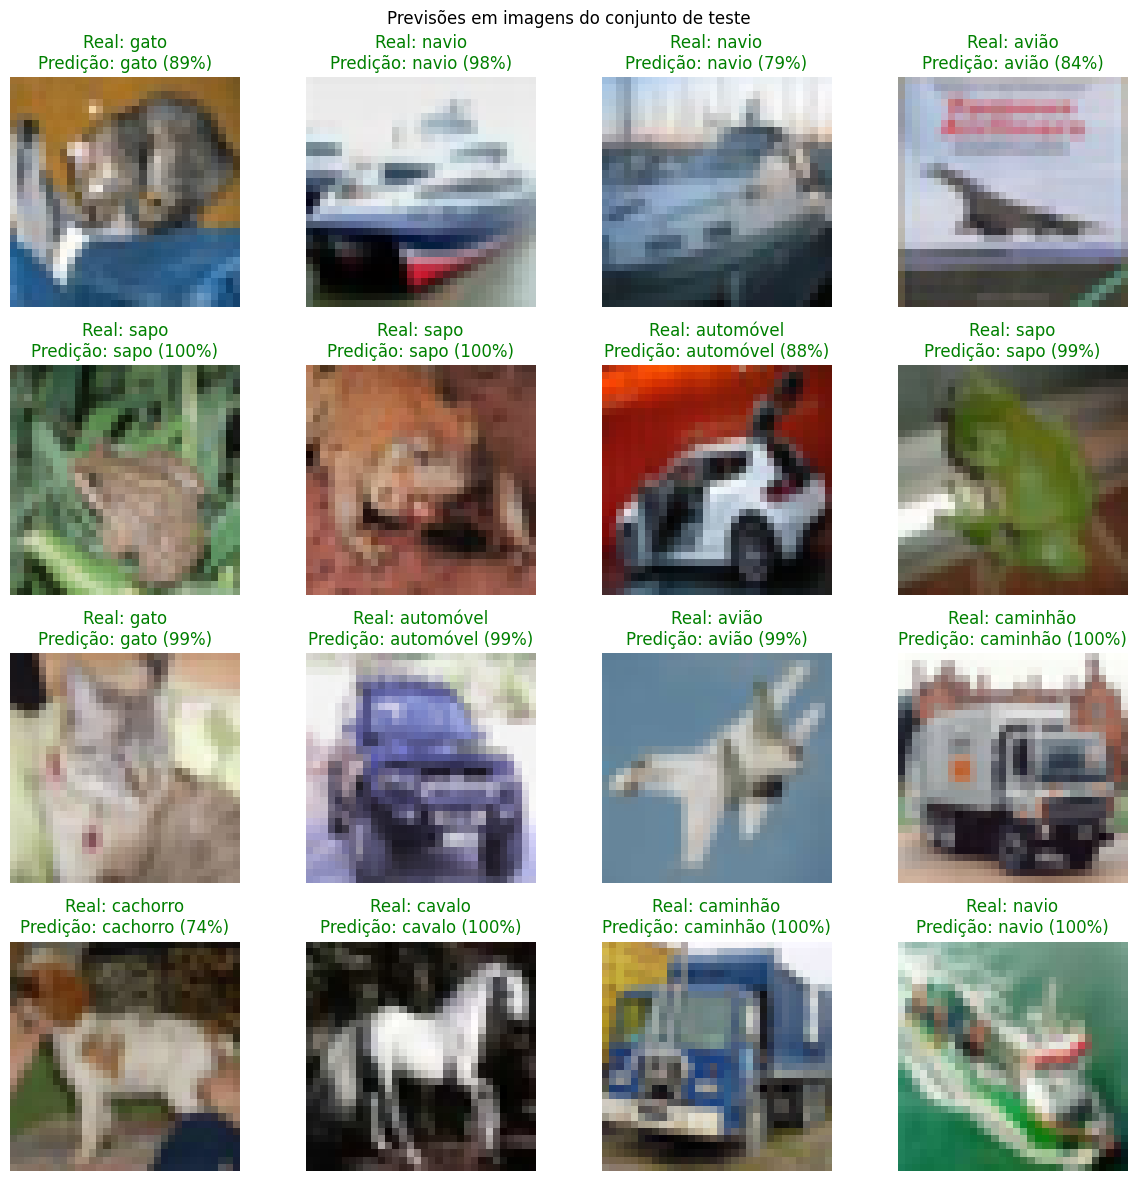

In [19]:
plt.figure(figsize=(12, 12))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_test[i])
    real = class_names[y_test[i]]
    pred = class_names[test_pred[i]]
    confidence = test_probs[i].max()
    color = "green" if y_test[i] == test_pred[i] else "red"
    plt.title(f"Real: {real}\nPredição: {pred} ({confidence:.0%})", color=color)
    plt.axis("off")
plt.suptitle("Previsões em imagens do conjunto de teste")
plt.tight_layout()
plt.show()

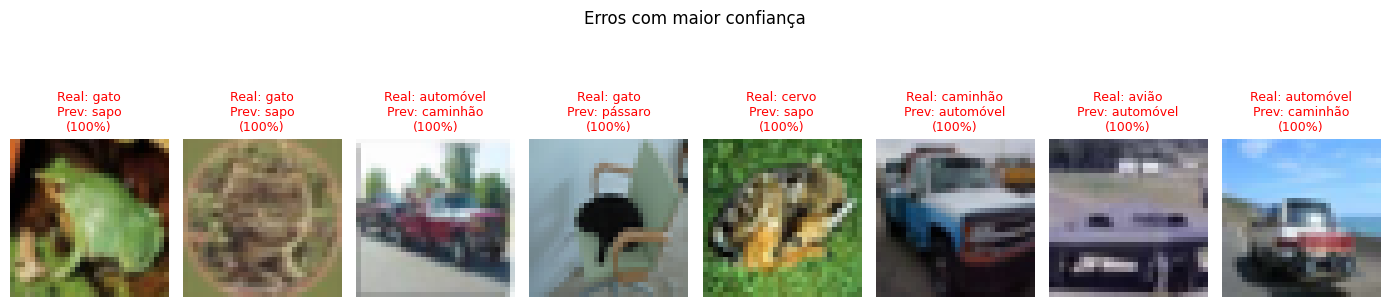

In [20]:
# Erros mais "confiantes": a rede errou com alta probabilidade
wrong = np.where(test_pred != y_test)[0]
most_confident_wrong = wrong[np.argsort(test_probs[wrong].max(axis=1))[::-1][:8]]

plt.figure(figsize=(14, 4))
for i, idx in enumerate(most_confident_wrong):
    plt.subplot(1, 8, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Real: {class_names[y_test[idx]]}\nPrev: {class_names[test_pred[idx]]}\n"
        f"({test_probs[idx].max():.0%})",
        color="red", fontsize=9,
    )
    plt.axis("off")
plt.suptitle("Erros com maior confiança")
plt.tight_layout()
plt.show()

## 10. Classificando uma imagem nova

Fluxo para uma imagem qualquer (por exemplo, uma foto do celular):

```
arquivo → load_img (redimensiona para 32×32) → img_to_array → /255 → modelo → softmax → classe
```

Para testar com uma foto sua, coloque o arquivo em `data/raw/` e troque o `IMAGE_PATH`.

Classe real: sapo


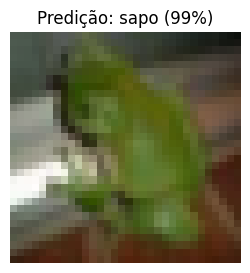

     sapo: 99.3%
  pássaro: 0.4%
    cervo: 0.2%


In [21]:
# Carrega o melhor modelo salvo pelo ModelCheckpoint
best_model = keras.models.load_model(MODEL_PATH)


def classify_image(image_path, model=best_model, top_k=3):
    # Mesmo pré-processamento do treino: 32×32 pixels e valores em [0, 1]
    img = load_img(image_path, target_size=(32, 32))
    x = img_to_array(img) / 255.0
    probs = model.predict(np.expand_dims(x, axis=0), verbose=0)[0]

    top = np.argsort(probs)[::-1][:top_k]

    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(f"Predição: {class_names[top[0]]} ({probs[top[0]]:.0%})")
    plt.axis("off")
    plt.show()

    for idx in top:
        print(f"{class_names[idx]:>9}: {probs[idx]:.1%}")


# Exemplo: salvamos uma imagem do teste como arquivo e classificamos a partir do arquivo
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_PATH = INTERIM_DIR / "exemplo_teste.png"
keras.utils.save_img(IMAGE_PATH, X_test_raw[7])

print("Classe real:", class_names[y_test[7]])
classify_image(IMAGE_PATH)

## Conclusão

- Uma imagem é um tensor **altura × largura × canais** com pixels de 0 a 255; normalizamos para
  [0, 1] antes do treino.
- A **convolução** detecta padrões locais com filtros, o **pooling** reduz o tamanho mantendo o
  essencial e as camadas **densas** com **softmax** decidem a classe.
- A **CNN base** mostra overfitting: o treino melhora e a validação estaciona.
- A **CNN melhorada** (Data Augmentation, Batch Normalization, Dropout e callbacks) generaliza
  melhor e tem acurácia bem maior no teste.
- A matriz de confusão mostra que os maiores erros estão entre **animais parecidos** (gato ×
  cachorro), o que faz sentido em imagens de apenas 32×32 pixels.
- O melhor modelo fica salvo em `models/classificador_cifar10.keras` e pode classificar
  imagens novas com o mesmo pré-processamento do treino.